# Prompt format vs. token usage: exploratory analysis

**Overall question:** how do properties of a prompt relate to the tokens an LLM uses when it writes Python code?

| | Experiment 1 (Part A) | Experiment 2 (Part B) |
|---|---|---|
| **Tasks** | 10 small coding tasks (`t01`–`t10`) | 6 tasks over real LoL esports data (`t11`–`t16`) |
| **Varied** | instruction `format`: `structured` vs `informal` | `data_format`: `csv` vs `xml` vs `prose`, **crossed with** instruction `format` |
| **Measured** | `input_tokens`, `output_tokens` + hidden unit tests (correctness) | `input_tokens`, `output_tokens` + a validity check (answers not graded) |
| **Calls** | 10 × 2 × 5 = 100 | 6 × 3 × 2 × 5 = 180 |

- **Controls:** same model, temperature, max output tokens, and system prompt on every call; no extended thinking.
- **Data:** Experiment 2 uses 20-row samples from the [Oracle's Elixir](https://oracleselixir.com) 2025 LoL esports match data.
- **Part C** looks across all 280 rows.

**Unit of analysis.** Each prompt is run 5 times, but those runs are repeated measurements of the *same* prompt, not independent samples. Statistical comparisons therefore use **per-task means**. Treating every row as independent would overstate certainty (pseudo-replication).

> The "How to read it" notes below explain each plot. Lines marked **Result:** describe the runs in `data/results.csv` (`qwen2.5-coder:7b` via Ollama, collected 2026-10-14). If you re-run the experiment, re-check them against the new numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
RESULTS_CSV = "../data/results.csv"
MODEL = "qwen2.5-coder:7b"   # analyze one model at a time (must match config.py)

FORMATS = ["structured", "informal"]
COLORS = {"structured": "#2a78d6", "informal": "#eb6834"}  # blue / orange (colorblind-safe pair)
NEUTRAL = "#8a8984"

DATA_FORMATS = ["csv", "xml", "prose"]
# green / violet / magenta: colorblind-safe as a set; markers and labels give a second cue
DATA_COLORS = {"csv": "#008300", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

all_rows = pd.read_csv(RESULTS_CSV)
all_rows = all_rows[all_rows["model"] == MODEL].copy()
all_rows["pass_rate"] = all_rows["tests_passed"] / all_rows["tests_total"]

df = all_rows[all_rows["data_format"] == "none"].copy()     # Experiment 1 -> Part A
exp2 = all_rows[all_rows["data_format"] != "none"].copy()   # Experiment 2 -> Part B
print(f"{len(all_rows)} rows for {MODEL}: {len(df)} in Experiment 1, {len(exp2)} in Experiment 2")
all_rows.head()

280 rows for qwen2.5-coder:7b: 100 in Experiment 1, 180 in Experiment 2


,task_id,format,data_format,run,model,input_tokens,output_tokens,tests_passed,tests_total,passed_all,stop_reason,timestamp,pass_rate
0,t05_roman,structured,none,3,qwen2.5-coder:7b,231,222,5,5,True,stop,2026-10-14T03:51:04+00:00,1.000000
1,t05_roman,structured,none,2,qwen2.5-coder:7b,231,173,5,5,True,stop,2026-10-14T03:51:07+00:00,1.000000
2,t10_lru_cache,structured,none,2,qwen2.5-coder:7b,281,170,8,8,True,stop,2026-10-14T03:51:11+00:00,1.000000
3,t01_fizzbuzz,informal,none,5,qwen2.5-coder:7b,155,72,5,5,True,stop,2026-10-14T03:51:12+00:00,1.000000
4,t07_duration,informal,none,1,qwen2.5-coder:7b,280,166,4,6,False,stop,2026-10-14T03:51:16+00:00,0.666667


## 0. The tasks

Everything below is read straight from the `tasks/` folder, so it always matches the prompts the model actually received. Change `EXAMPLE_TASK` to view a different pair.

In [2]:
import html
import json
import re
import textwrap
from pathlib import Path
from IPython.display import HTML, Markdown

TASKS_DIR = Path("../tasks")
EXAMPLE_TASK = "t04_password"

all_task_dirs = sorted(p for p in TASKS_DIR.glob("t*") if p.is_dir())
EXP1_TASKS = [p.name for p in all_task_dirs if not (p / "data_csv.txt").exists()]
EXP2_TASKS = [p.name for p in all_task_dirs if (p / "data_csv.txt").exists()]

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

def wrapped(text, width=76):
    """Wrap long lines so the prompts fit side by side (keeps the original line breaks)."""
    return "\n".join(textwrap.fill(line, width) if line else "" for line in text.splitlines())

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>{fmt}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(wrapped(read_task_file(EXAMPLE_TASK, fmt + ".txt")))}</pre></td>'
    for fmt in FORMATS
)
display(Markdown(f"### Example: `{EXAMPLE_TASK}`, both prompts"))
display(HTML(f"<table><tr>{columns}</tr></table>"))

### Example: `t04_password`, both prompts

"structured.txt## Goal Write a function that checks whether a password is strong. ## Input `validate_password(pw: str) -> bool` ## Requirements 1. The password must be at least 8 characters long. 2. It must contain at least one uppercase letter. 3. It must contain at least one lowercase letter. 4. It must contain at least one digit. 5. It must contain at least one of these special characters: ! @ # $ % 6. It must not contain any spaces. ## Output Return True if every requirement is met, otherwise False. Respond with only Python code.","informal.txtHey, can you write me a little Python function called validate_password(pw) that tells me whether a password is good enough? It should give back True if it passes every rule, otherwise False. Spaces aren't allowed anywhere in it, and it needs at least one digit in there somewhere. Oh, and it has to be at least 8 characters long. I also want at least one uppercase letter and at least one lowercase letter, plus at least one of the special characters ! @ # $ or %. Just send back the Python code, nothing else."


In [3]:
# The checklist maps every requirement to where it appears in each prompt, and to its hidden test.
display(Markdown(read_task_file(EXAMPLE_TASK, "checklist.md")))

# t04_password checklist

| Req | Requirement | Structured | Informal (quoted phrase) | Test |
|---|---|---|---|---|
| R1 | length >= 8 | Requirements #1 | "it has to be at least 8 characters long" | `test_r1_min_length` |
| R2 | >= 1 uppercase | Requirements #2 | "at least one uppercase letter" | `test_r2_uppercase` |
| R3 | >= 1 lowercase | Requirements #3 | "at least one lowercase letter" | `test_r3_lowercase` |
| R4 | >= 1 digit | Requirements #4 | "it needs at least one digit in there somewhere" | `test_r4_digit` |
| R5 | >= 1 of ! @ # $ % | Requirements #5 | "at least one of the special characters ! @ # $ or %" | `test_r5_special_character` |
| R6 | no spaces | Requirements #6 | "Spaces aren't allowed anywhere in it" | `test_r6_no_spaces` |

Shared by both prompts: name `validate_password(pw)`, returns True/False, "only Python code".


**How to read it:** both prompts ask for exactly the same function and the same requirements, so only the presentation differs. The structured version uses labeled sections and a numbered list. The informal version is one conversational paragraph, with the requirements in a different order. The checklist shows where each requirement (R1, R2, …) appears in both, which is how we confirm neither prompt asks for more than the other.

### All 10 Experiment 1 tasks

In [4]:
task_rows = []
for task_id in EXP1_TASKS:
    structured = read_task_file(task_id, "structured.txt")
    informal = read_task_file(task_id, "informal.txt")
    task_rows.append({
        "task_id": task_id,
        # same counting rules as src/check_tasks.py: requirement rows in the checklist, test functions
        "requirements": len(re.findall(r"^\| R\d+ \|", read_task_file(task_id, "checklist.md"), re.MULTILINE)),
        "tests": len(re.findall(r"^def test_", read_task_file(task_id, "test_solution.py"), re.MULTILINE)),
        "structured words": len(structured.split()),
        "informal words": len(informal.split()),
    })
tasks_table = pd.DataFrame(task_rows).set_index("task_id")

# Prompt length in tokens, as the model counted it (includes the system prompt; identical on every run).
prompt_tokens = df.groupby(["task_id", "format"])["input_tokens"].mean().unstack()[FORMATS].round(0).astype(int)
tasks_table["structured input tokens"] = prompt_tokens["structured"]
tasks_table["informal input tokens"] = prompt_tokens["informal"]
tasks_table.loc["total"] = tasks_table.sum()
tasks_table

,requirements,tests,structured words,informal words,structured input tokens,informal input tokens
task_id,,,,,,
t01_fizzbuzz,5,5,112,96,189,155
t02_whitespace,4,4,90,104,144,154
t03_chunk,5,5,106,106,176,153
t04_password,6,6,95,95,148,137
t05_roman,5,5,105,100,231,217
t06_wordfreq,6,6,138,135,224,201
t07_duration,6,6,172,166,310,280
t08_intervals,6,6,126,123,221,197
t09_transactions,7,7,164,149,271,231


**How to read it:** `requirements` should equal `tests` in every row, because each requirement has exactly one hidden test (58 in total). The word counts measure the prompt text itself. The input-token columns are the length as the model counted it, including the short system prompt that's the same for every call. 

**Result:** the two formats use almost the same number of words (1,271 vs 1,246 in total, and identical in `t03` and `t04`). Yet the structured prompt takes more tokens in 9 of 10 tasks (2,195 vs 1,979 in total). In `t10_lru_cache` the informal prompt has *more* words (172 vs 163) but still *fewer* tokens (254 vs 281). So the extra input tokens come from formatting, not wording: the `##` headings, numbered list markers, backticks and line breaks each cost tokens. Section 5 checks whether this length gap could explain the difference in output tokens.

### Experiment 2 tasks: the same data written three ways

Each Experiment 2 prompt is an instruction template (structured or informal) with a `{DATA}` slot. The slot is filled with the same 20 rows as CSV, XML, or prose, all generated from one `sample.json` by `scripts/make_data_tasks.py`. Below are the first few rows of one task in each format. Change `EXAMPLE_DATA_TASK` to view another.

In [5]:
EXAMPLE_DATA_TASK = "t11_side_winrate"

def preview(text, data_format, n=4):
    """The first n rows of a data block (prose rows are sentences, so cut by characters instead)."""
    if data_format == "prose":
        return textwrap.fill(text[:420], 60) + " ..."
    lines = text.splitlines()
    return "\n".join(lines[:n + 1]) + "\n..."   # +1 for the CSV header / opening <rows> tag

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>data_{d}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(preview(read_task_file(EXAMPLE_DATA_TASK, f"data_{d}.txt"), d))}</pre></td>'
    for d in DATA_FORMATS
)
display(Markdown(f"#### `{EXAMPLE_DATA_TASK}`: first rows in each data format"))
display(HTML(f"<table><tr>{columns}</tr></table>"))
display(Markdown("#### Its structured instruction template (the data goes where `{DATA}` is)"))
display(HTML(f'<pre style="white-space:pre-wrap">{html.escape(wrapped(read_task_file(EXAMPLE_DATA_TASK, "structured.txt")))}</pre>'))

#### `t11_side_winrate`: first rows in each data format

"data_csv.txtgame,team,side,result,game_minutes G01,DN Freecs,blue,loss,34.1 G01,Dplus KIA,red,win,34.1 G02,BNK FEARX,blue,loss,40.1 G02,Gen.G,red,win,40.1 ...",data_xml.txt<rows> <row><game>G01</game><team>DN Freecs</team><side>blue</side><result>loss</result><game_minutes>34.1</game_minutes></row> <row><game>G01</game><team>Dplus KIA</team><side>red</side><result>win</result><game_minutes>34.1</game_minutes></row> <row><game>G02</game><team>BNK FEARX</team><side>blue</side><result>loss</result><game_minutes>40.1</game_minutes></row> <row><game>G02</game><team>Gen.G</team><side>red</side><result>win</result><game_minutes>40.1</game_minutes></row> ...,"data_prose.txtIn game G01, DN Freecs played on the blue side and lost; the game lasted 34.1 minutes. In game G01, Dplus KIA played on the red side and won; the game lasted 34.1 minutes. In game G02, BNK FEARX played on the blue side and lost; the game lasted 40.1 minutes. In game G02, Gen.G played on the red side and won; the game lasted 40.1 minutes. In game G03, Dplus KIA played on the blue side and won; the game lasted 27.5 min ..."


#### Its structured instruction template (the data goes where `{DATA}` is)

### All 6 Experiment 2 tasks

In [6]:
data_rows = []
for task_id in EXP2_TASKS:
    row = {"task_id": task_id, "rows": len(json.loads(read_task_file(task_id, "sample.json")))}
    for d in DATA_FORMATS:
        row[f"{d} chars"] = len(read_task_file(task_id, f"data_{d}.txt"))
    data_rows.append(row)
data_table = pd.DataFrame(data_rows).set_index("task_id")

# Input tokens per data format (averaged over both instruction formats), as the model counted them.
input_by_format = exp2.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()
for d in DATA_FORMATS:
    if d in input_by_format:
        data_table[f"{d} input tokens"] = input_by_format[d].round(0)
data_table

,rows,csv chars,xml chars,prose chars,csv input tokens,xml input tokens,prose input tokens
task_id,,,,,,,
t11_side_winrate,20,627,2487,1752,524.0,1062.0,722.0
t12_gold_lead,20,617,2477,2062,515.0,1168.0,825.0
t13_objectives,20,794,3397,2412,558.0,1417.0,855.0
t14_mid_kda,20,801,3287,1812,574.0,1356.0,716.0
t15_jungle_picks,20,459,2084,1209,380.0,894.0,498.0
t16_support_vision,20,803,3639,2064,572.0,1354.0,787.0


**How to read it:** the `chars` columns measure the data block alone. The `input tokens` columns are the whole prompt (instructions + data + system prompt) as the model counted it, averaged over the structured and informal versions.

**Result:** the XML data block is about 4× as many characters as the CSV one (2,084–3,639 vs 459–803), because every value is wrapped in an opening and closing tag. As whole prompts, XML costs 2.0–2.5× the CSV prompt in tokens, and prose 1.25–1.6×.

# Part A: Experiment 1 (instruction format, coding tasks)

Sections 1–10 use only the Experiment 1 rows (`data_format == "none"`), so the numbers here are the same as before Experiment 2 was added.

## 1. Sanity checks

In [7]:
print("Runs per task x format (every cell should equal N_RUNS):")
display(df.pivot_table(index="task_id", columns="format", values="run", aggfunc="count"))

print("stop_reason counts ('length' or 'max_tokens' would mean a truncated answer):")
display(df["stop_reason"].value_counts())

print("Missing values per column:")
display(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "none")

Runs per task x format (every cell should equal N_RUNS):


format,informal,structured
task_id,,
t01_fizzbuzz,5,5
t02_whitespace,5,5
t03_chunk,5,5
t04_password,5,5
t05_roman,5,5
t06_wordfreq,5,5
t07_duration,5,5
t08_intervals,5,5
t09_transactions,5,5


stop_reason counts ('length' or 'max_tokens' would mean a truncated answer):


stop_reason
stop    100
Name: count, dtype: int64

Missing values per column:


'none'

**How to read it:** every task × format cell should show the same count (N_RUNS). A `length` (Ollama) or `max_tokens` (Claude) stop reason means a response was cut off, and its `output_tokens` is capped, not natural. Investigate those rows before trusting the token comparisons.

**Result:** all 100 rows are present (5 per task × format), every response ended normally (`stop`), and nothing is missing. No answer was cut off, so the output-token counts are natural lengths.

## 2. Summary table: tokens by format

In [8]:
summary = df.groupby("format")[["input_tokens", "output_tokens"]].agg(["mean", "median", "std"]).round(1)
summary.loc[FORMATS]

input_tokens              output_tokens             
                   mean median   std          mean median   std
format                                                         
structured        219.5  222.5  53.8         143.0  155.5  60.1
informal          197.9  199.0  46.1         126.9  118.0  62.7

**How to read it:** this table pools all tasks and runs, so it's a first look and not the test. Compare the means and medians between rows. A big gap between mean and median suggests a few long responses are pulling the mean.

**Result:** informal prompts were shorter to send (mean 197.9 vs 219.5 input tokens) and got shorter answers (mean 126.9 vs 143.0 output tokens; median 118 vs 155.5). The standard deviations (~60 output tokens) are much bigger than the gap, because tasks differ a lot in size. That's why the paired comparison below matters.

## 3. Distribution of output tokens by format

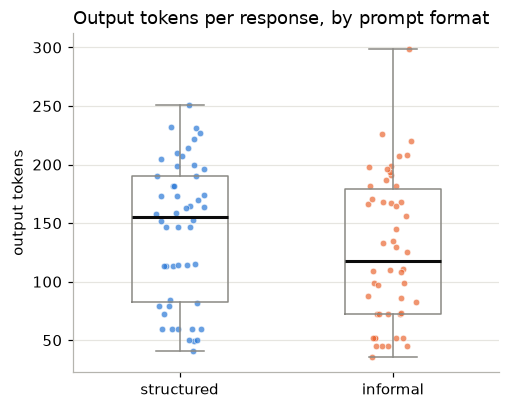

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
data = [df.loc[df["format"] == f, "output_tokens"] for f in FORMATS]
ax.boxplot(data, tick_labels=FORMATS, widths=0.45, showfliers=False,
           medianprops={"color": "#0b0b0b", "linewidth": 2},
           boxprops={"color": NEUTRAL}, whiskerprops={"color": NEUTRAL}, capprops={"color": NEUTRAL})
rng = np.random.default_rng(SEED)
for i, (f, values) in enumerate(zip(FORMATS, data), start=1):
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(i + jitter, values, s=18, color=COLORS[f], alpha=0.7, edgecolor="white", linewidth=0.5)
ax.set_ylabel("output tokens")
ax.set_title("Output tokens per response, by prompt format", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

**How to read it:** the box spans the middle 50% of responses and the black line is the median. Each dot is one response. Shifted or differently sized boxes suggest format matters, but tasks differ a lot in how much code they need, so this pooled view mixes task difficulty with format. Section 4 controls for that.

**Result:** the informal box sits somewhat lower (median 118 vs 155.5), but the two distributions overlap heavily. On its own this plot can't separate format from task size.

## 4. Paired comparison per task (slope plot)

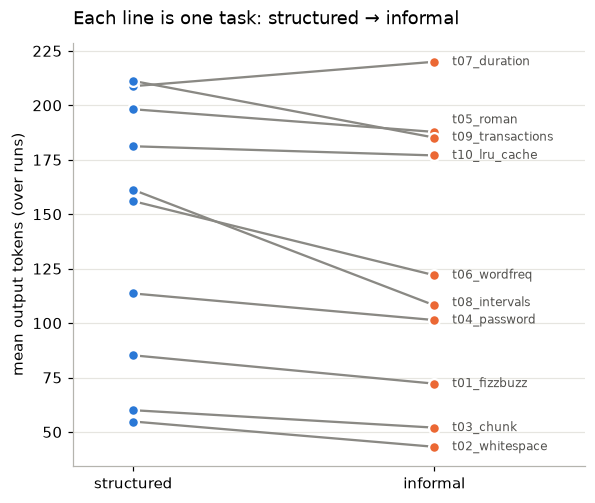

Tasks where informal used MORE output tokens: 1 of 10


In [10]:
task_means = df.groupby(["task_id", "format"])[["input_tokens", "output_tokens", "pass_rate"]].mean().unstack()
out = task_means["output_tokens"][FORMATS]

fig, ax = plt.subplots(figsize=(6, 5))
for task_id, row in out.iterrows():
    ax.plot([0, 1], [row["structured"], row["informal"]], color=NEUTRAL, linewidth=1.5, zorder=1)
for x, f in enumerate(FORMATS):
    ax.scatter([x] * len(out), out[f], s=50, color=COLORS[f], edgecolor="white", linewidth=1.5, zorder=2)

# Task labels at the right end, nudged apart so close values don't overlap.
min_gap = (out.values.max() - out.values.min()) * 0.045
label_y = None
for task_id, y in out["informal"].sort_values().items():
    label_y = y if label_y is None else max(y, label_y + min_gap)
    ax.text(1.06, label_y, task_id, va="center", fontsize=8, color="#52514e")
ax.set_ylim(top=max(ax.get_ylim()[1], label_y + min_gap))  # keep the top label inside the plot

ax.set_xticks([0, 1], FORMATS)  # the x-axis names the formats, so no legend is needed
ax.set_xlim(-0.2, 1.5)
ax.set_ylabel("mean output tokens (over runs)")
ax.set_title("Each line is one task: structured → informal", loc="left", pad=12)
ax.grid(axis="x", visible=False)
plt.show()

print(f"Tasks where informal used MORE output tokens: {(out['informal'] > out['structured']).sum()} of {len(out)}")

**How to read it:** each line connects the same task under both formats, so differences in task difficulty cancel out. If most lines slope the same way, format has a consistent effect. If they cross in both directions, the effect depends on the task or is noise.

**Result:** 9 of 10 lines slope downward: informal prompts led to fewer output tokens in every task except `t07_duration` (+11). The biggest drops were `t08_intervals` (−53), `t06_wordfreq` (−34), and `t09_transactions` (−26). The smallest were `t10_lru_cache` (−4) and `t03_chunk` (−8). The effect is consistent in direction but varies in size.

## 5. Input-token gap per task (confound check)

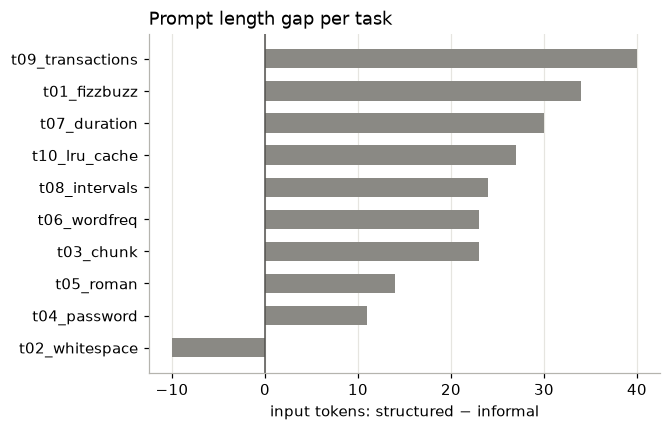

Spearman correlation between input gap and output gap across tasks: rho=0.07, p=0.854


In [11]:
inp = task_means["input_tokens"][FORMATS]
input_gap = (inp["structured"] - inp["informal"]).sort_values()
output_gap = (out["structured"] - out["informal"]).loc[input_gap.index]

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(input_gap.index, input_gap.values, color=NEUTRAL, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("input tokens: structured − informal")
ax.set_title("Prompt length gap per task", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

rho, p = stats.spearmanr(input_gap, output_gap)
print(f"Spearman correlation between input gap and output gap across tasks: rho={rho:.2f}, p={p:.3f}")

**How to read it:** bars to the right mean the structured prompt was longer for that task. Prompt length is a possible **confound**: if longer prompts lead to longer answers, an output difference could come from length rather than format. A strong correlation between the input gap and the output gap would point that way. With only 10 tasks, treat this as a warning sign, not proof.

**Result:** the structured prompt was longer in 9 of 10 tasks (by 11–40 tokens). The exception is `t02_whitespace`, where the informal prompt was 10 tokens *longer*, yet its answers were still 12 tokens *shorter*. Across tasks, the input gap barely tracks the output gap (Spearman ρ = 0.07, p = 0.85). Prompt length therefore doesn't appear to explain the output difference, though with 10 tasks we can't rule it out completely.

## 6. Run-to-run variability

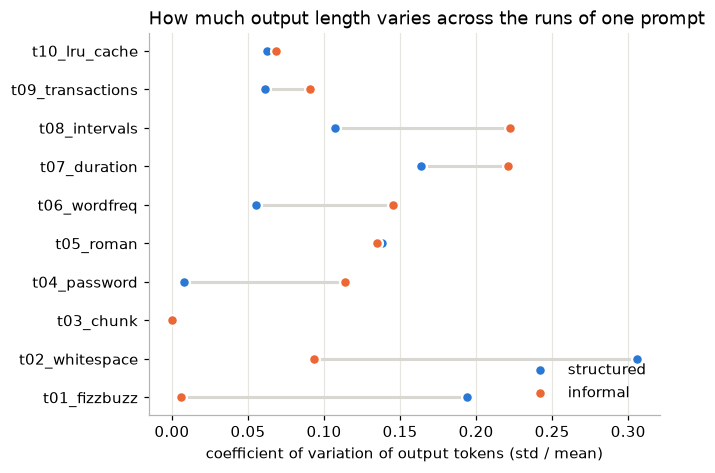

mean                 std                  cv           
format           informal structured informal structured informal structured
task_id                                                                     
t01_fizzbuzz         72.2       85.2     0.45      16.51     0.01       0.19
t02_whitespace       43.2       54.8     4.02      16.75     0.09       0.31
t03_chunk            52.0       60.0     0.00       0.00     0.00       0.00
t04_password        101.4      113.6    11.55       0.89     0.11       0.01
t05_roman           187.8      198.2    25.35      27.37     0.13       0.14
t06_wordfreq        122.0      156.0    17.69       8.60     0.15       0.06
t07_duration        220.0      208.8    48.66      34.18     0.22       0.16
t08_intervals       108.2      161.2    24.08      17.25     0.22       0.11
t09_transactions    185.2      211.2    16.81      12.95     0.09       0.06
t10_lru_cache       177.0      181.2    12.08      11.30     0.07       0.06

In [12]:
var = df.groupby(["task_id", "format"])["output_tokens"].agg(["mean", "std"])
var["cv"] = var["std"] / var["mean"]
cv = var["cv"].unstack()[FORMATS]

fig, ax = plt.subplots(figsize=(6, 4.5))
y = np.arange(len(cv))
ax.hlines(y, cv.min(axis=1), cv.max(axis=1), color="#d8d7d1", linewidth=2, zorder=1)
for f in FORMATS:
    ax.scatter(cv[f], y, s=50, color=COLORS[f], edgecolor="white", linewidth=1.5, zorder=2, label=f)
ax.set_yticks(y, cv.index)
ax.set_xlabel("coefficient of variation of output tokens (std / mean)")
ax.set_title("How much output length varies across the runs of one prompt", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.show()

var.round(2).unstack()

**How to read it:** the coefficient of variation (CV) is the standard deviation divided by the mean, so tasks with different lengths can be compared. A CV of 0.10 means runs typically differ by about 10% from their average. If one format is consistently more variable, its prompts leave the model more room to choose how much to write. High variability overall also means more runs would be needed to detect small format effects.

**Result:** there's no consistent pattern. Informal answers varied more for `t04`, `t06`, `t07`, `t08`; structured answers varied more for `t01` and `t02`. `t03_chunk` produced the *identical* answer in all 5 runs of both formats (CV = 0), so for simple tasks this model at temperature 0.7 often repeats itself. Most CVs are below 0.2, meaning run-to-run differences are typically smaller than 20% of the mean.

## 7. Output tokens vs. correctness

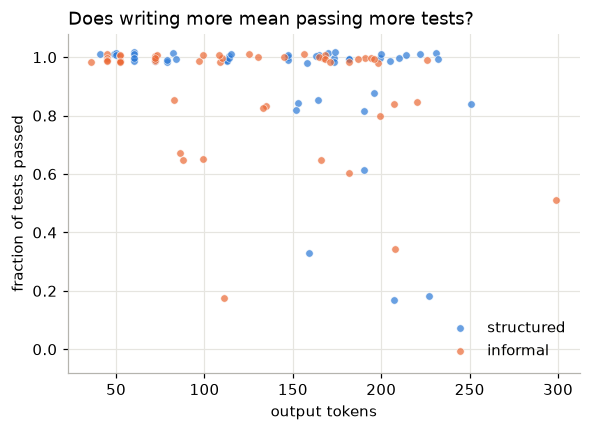

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
rng = np.random.default_rng(SEED)
for f in FORMATS:
    sub = df[df["format"] == f]
    jitter = rng.uniform(-0.02, 0.02, size=len(sub))
    ax.scatter(sub["output_tokens"], sub["pass_rate"] + jitter, s=24, color=COLORS[f],
               alpha=0.7, edgecolor="white", linewidth=0.5, label=f)
ax.set_xlabel("output tokens")
ax.set_ylabel("fraction of tests passed")
ax.set_ylim(-0.08, 1.08)
ax.set_title("Does writing more mean passing more tests?", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

**How to read it:** each dot is one response, with a small vertical jitter so overlapping dots stay visible. If correct answers (top row) cluster at a certain length, length and correctness are linked. If one format's dots sit lower, that format produced more failing code, and a token "saving" might just come from missing requirements.

**Result:** most responses pass every test regardless of length, and the failures are spread across short and long answers in both colors. There's no visible sign that shorter (informal) answers failed more often because they were shorter.

## 8. Output tokens per fully correct solution

In [14]:
eff = df.groupby("format").agg(
    responses=("output_tokens", "size"),
    total_output_tokens=("output_tokens", "sum"),
    fully_correct=("passed_all", "sum"),
    mean_pass_rate=("pass_rate", "mean"),
).loc[FORMATS]
eff["tokens_per_correct_solution"] = (eff["total_output_tokens"] / eff["fully_correct"]).round(1)
eff["mean_pass_rate"] = eff["mean_pass_rate"].round(3)
eff

,responses,total_output_tokens,fully_correct,mean_pass_rate,tokens_per_correct_solution
format,,,,,
structured,50,7151,40,0.926,178.8
informal,50,6345,36,0.905,176.2


**How to read it:** `tokens_per_correct_solution` is the total output tokens spent divided by the number of responses that passed every test. It combines cost and quality: a format that writes fewer tokens but fails more often can still be *less* efficient by this measure.

**Result:** structured prompts gave slightly more fully correct answers (40/50 vs 36/50; mean pass rate 0.926 vs 0.905), but used more tokens. Per fully correct solution the two formats come out nearly identical: 178.8 (structured) vs 176.2 (informal) output tokens. So informal's raw token saving is roughly cancelled by its slightly lower success rate.

## 9. Paired statistical comparison (within task)

In [15]:
def paired_comparison(metric, n_boot=10_000):
    """Compare informal vs structured using per-task means (one pair per task)."""
    means = task_means[metric][FORMATS]
    diff = means["informal"] - means["structured"]

    # Wilcoxon signed-rank: are the differences centered on 0? (Fails if every diff is 0.)
    try:
        w_stat, w_p = stats.wilcoxon(diff)
    except ValueError:
        w_stat, w_p = np.nan, np.nan

    # Bootstrap: resample the tasks with replacement and recompute the mean difference.
    rng = np.random.default_rng(SEED)
    samples = rng.choice(diff.to_numpy(), size=(n_boot, len(diff)), replace=True)
    boot_means = samples.mean(axis=1)
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    return {
        "metric": metric,
        "n_tasks": len(diff),
        "mean_diff (informal - structured)": round(diff.mean(), 3),
        "median_diff": round(diff.median(), 3),
        "bootstrap 95% CI": f"[{ci_low:.3f}, {ci_high:.3f}]",
        "wilcoxon_stat": w_stat,
        "wilcoxon_p": round(w_p, 4) if not np.isnan(w_p) else np.nan,
    }

pd.DataFrame([paired_comparison(m) for m in ["output_tokens", "input_tokens", "pass_rate"]]).set_index("metric")

,n_tasks,mean_diff (informal - structured),median_diff,bootstrap 95% CI,wilcoxon_stat,wilcoxon_p
metric,,,,,,
output_tokens,10,-16.120,-11.9,"[-27.260, -6.380]",4.0,0.0137
input_tokens,10,-21.600,-23.5,"[-29.100, -12.800]",1.0,0.0039
pass_rate,10,-0.021,0.0,"[-0.071, 0.027]",5.0,0.3125


**How to read it:**
- **mean_diff** is positive when informal prompts used more tokens (or passed more tests) than structured ones, averaged over tasks.
- **Bootstrap 95% CI:** we resample the 10 tasks 10,000 times and take the middle 95% of the resampled mean differences. If the interval excludes 0, the difference is unlikely to be just task-to-task noise.
- **Wilcoxon signed-rank p-value:** a non-parametric paired test. It asks whether the per-task differences are consistently on one side of zero, without assuming they are normally distributed.
- **Power caveat:** with only 10 pairs the test can detect only fairly consistent effects; the smallest possible two-sided p-value is about 0.002 (all 10 differences in the same direction). A non-significant result means "no evidence of a difference at this sample size", not "no difference".

**Result:** the per-task output difference is −16.1 tokens on average (informal − structured; median −11.9). The bootstrap 95% CI [−27.3, −6.4] excludes 0, and the Wilcoxon test gives p = 0.014, so informal prompts led to modestly shorter answers. Input tokens were also lower for informal (−21.6, CI [−29.1, −12.8], p = 0.004), but that's just the prompts being shorter. Pass rate shows no significant difference (−0.02, CI [−0.07, 0.03], p = 0.31).

## 9b. Where do the extra tokens go?

In [16]:
import re
import sys
from pathlib import Path

sys.path.insert(0, "../src")  # also used by B7 below
from evaluate import extract_code

rows = []
safe_model = MODEL.replace(":", "-").replace("/", "-")
for path in Path("../data/raw").glob(f"*__{safe_model}.txt"):
    task_id, fmt, data_format, run, _ = path.stem.split("__")
    if data_format != "none":
        continue  # Experiment 1 only
    code_text = extract_code(path.read_text(encoding="utf-8"))
    lines = [line for line in code_text.splitlines() if line.strip()]
    rows.append({
        "format": fmt,
        "comment_lines": sum(line.strip().startswith("#") for line in lines),
        "code_lines": sum(not line.strip().startswith("#") for line in lines),
    })
pd.DataFrame(rows).groupby("format").mean().round(2).loc[FORMATS]

,comment_lines,code_lines
format,,
structured,0.80,13.8
informal,0.08,13.0


**How to read it:** this reads the saved raw answers (`data/raw/`, not committed to git, so it needs a local run) and counts comment lines and code lines per answer.

**Result:** structured answers averaged 0.8 comment lines vs 0.1 for informal, plus slightly more code (13.8 vs 13.0 non-comment lines). Neither format got prose explanations or usage examples, so the model followed "only Python code" in both. Part of the extra length from structured prompts is comments, perhaps mirroring the labeled, list-like requirements; the rest is slightly more code.

## 10. Conclusions and limitations

**Conclusions:** for `qwen2.5-coder:7b`, informal prompts led to modestly but consistently shorter answers: about 16 fewer output tokens per task (≈11%), shorter in 9 of 10 tasks, 95% CI [−27, −6], Wilcoxon p = 0.014. The informal prompts were also shorter to send, but the size of that gap doesn't track the output difference across tasks, so prompt length doesn't seem to be the explanation. Correctness didn't differ significantly, but structured prompts produced slightly more fully correct solutions (40 vs 36 of 50). Measured as output tokens per *fully correct* solution, the two formats are essentially tied (~177–179). In short, informal prompting saved tokens per call without a clear quality cost in this sample, but the saving roughly disappears once failed attempts are counted.

**Limitations to discuss:**
- **One model** (`qwen2.5-coder:7b`, a small open-source model run locally) at one temperature; results may not carry over to larger commercial models (e.g. Claude, GPT) or to other temperatures.
- **One prompt pair per task:** the specific wording of each informal paragraph is mixed in with "informality" itself. More paraphrases per format would separate the two.
- **Small sample:** 10 tasks means low statistical power and wide confidence intervals.
- **Prompt length differs between formats** (section 5), which is a possible confound.
- **Small, self-contained tasks:** real-world coding prompts are longer and messier.

# Part B: Experiment 2 (data format × instruction format, LoL data tasks)

The model gets 20 rows of League of Legends esports data and must write Python that **includes the data in the code** and defines `q1()`–`q3()`. The answers are **not graded**: this experiment is about token usage. Each response gets a validity check instead, so a "cheap" response that skipped the work isn't mistaken for an efficient one.

## B1. Sanity checks and validity

In [17]:
print("Runs per task x instruction format x data format (every cell should equal N_RUNS):")
display(exp2.pivot_table(index="task_id", columns=["format", "data_format"], values="run", aggfunc="count"))
print("stop_reason counts:")
display(exp2["stop_reason"].value_counts())

# Validity = both checks passed: q1-q3 run, and every row of the data appears in the code.
exp2["valid"] = exp2["passed_all"]
print("Share of valid responses (data format x instruction format):")
display(exp2.pivot_table(index="data_format", columns="format", values="valid", aggfunc="mean").loc[DATA_FORMATS, FORMATS].round(2))
print("Checks passed per response (2 = valid; 1 = usually 'contains all the data but crashed'):")
display(exp2.groupby("data_format")["tests_passed"].value_counts().unstack(fill_value=0).loc[DATA_FORMATS])
invalid = exp2[~exp2["valid"]]
print(f"Invalid responses: {len(invalid)} of {len(exp2)}")
display(invalid[["task_id", "format", "data_format", "run", "tests_passed", "output_tokens"]])

valid = exp2[exp2["valid"]].copy()
valid["total_tokens"] = valid["input_tokens"] + valid["output_tokens"]

Runs per task x instruction format x data format (every cell should equal N_RUNS):


format             informal           structured          
data_format             csv prose xml        csv prose xml
task_id                                                   
t11_side_winrate          5     5   5          5     5   5
t12_gold_lead             5     5   5          5     5   5
t13_objectives            5     5   5          5     5   5
t14_mid_kda               5     5   5          5     5   5
t15_jungle_picks          5     5   5          5     5   5
t16_support_vision        5     5   5          5     5   5

stop_reason counts:


stop_reason
stop    180
Name: count, dtype: int64

Share of valid responses (data format x instruction format):


format,structured,informal
data_format,,
csv,0.97,0.90
xml,1.00,0.80
prose,0.87,0.73


Checks passed per response (2 = valid; 1 = usually 'contains all the data but crashed'):


tests_passed,1,2
data_format,,
csv,4,56
xml,6,54
prose,12,48


Invalid responses: 22 of 180


,task_id,format,data_format,run,tests_passed,output_tokens
111,t16_support_vision,informal,prose,1,1,668
120,t15_jungle_picks,informal,xml,1,1,956
131,t13_objectives,structured,prose,1,1,811
140,t15_jungle_picks,informal,xml,5,1,828
149,t11_side_winrate,structured,csv,5,1,706
163,t15_jungle_picks,informal,prose,5,1,828
166,t11_side_winrate,informal,prose,5,1,653
183,t15_jungle_picks,informal,xml,3,1,889
184,t11_side_winrate,informal,xml,4,1,1059
185,t13_objectives,structured,prose,3,1,925


**How to read it:** every cell of the first table should equal N_RUNS, and every stop reason should be `stop`. A response is **invalid** if its code crashed or if some rows of the data are missing from it. The two checks are independent, so a response scoring 1 of 2 either contains all the data but crashed, or runs but left rows out. The raw response in `data/raw/` tells which. Every chart below uses **valid responses only**, so the token numbers describe complete work.

**Result:** all 180 rows are present (5 per cell), and every response ended normally. **158 of 180 (88%) are valid**: CSV 56/60, XML 54/60, prose 48/60. Informal instructions were less often valid in every data format (0.90 / 0.80 / 0.73, against 0.97 / 1.00 / 0.87 for structured). Reading the 22 invalid answers: **20 contain all the data but crash** with ordinary bugs (`NameError`, `KeyError`, `ZeroDivisionError`, a syntax error). Only **2 skipped the data**: `t13` informal XML run 4 copied 2 rows and then wrote `# ... (rest of the data)`, and `t11` informal prose run 3 replaced the rows with an invented per-team summary. Shortcutting was rare (2 of 180).

## B2. Summary table: tokens by data format and instruction format

In [18]:
summary2 = valid.groupby(["data_format", "format"])[["input_tokens", "output_tokens", "total_tokens"]].agg(["mean", "median"]).round(0)
summary2.loc[DATA_FORMATS]

input_tokens         output_tokens          \
                               mean  median          mean  median   
data_format format                                                  
csv         informal          525.0   546.0        1050.0  1139.0   
            structured        531.0   570.0        1037.0  1042.0   
xml         informal         1240.0  1342.0        1141.0  1146.0   
            structured       1219.0  1272.0        1097.0  1100.0   
prose       informal          713.0   714.0         837.0   796.0   
            structured        731.0   729.0         834.0   766.0   

                       total_tokens          
                               mean  median  
data_format format                           
csv         informal         1575.0  1699.0  
            structured       1569.0  1567.0  
xml         informal         2381.0  2488.0  
            structured       2316.0  2372.0  
prose       informal         1550.0  1534.0  
            structured       1565.0  1543.0

**How to read it:** input tokens show what each data format costs to *send*. Output tokens show what it costs the model to *write the data back out* as Python. Total is the sum, i.e. the cost of one complete request.

**Result:** per request, CSV prompts average about 528 input tokens, prose about 722, and XML about 1,230. Output runs the other way for prose: CSV about 1,044, XML about 1,119, **prose about 836**. In **total**, prose (~1,558) and CSV (~1,572) cost about the same, while XML (~2,349) costs about 50% more. Within a data format, structured vs informal instructions change output by at most ~45 tokens.

## B3. Output tokens across data formats (interaction plot)

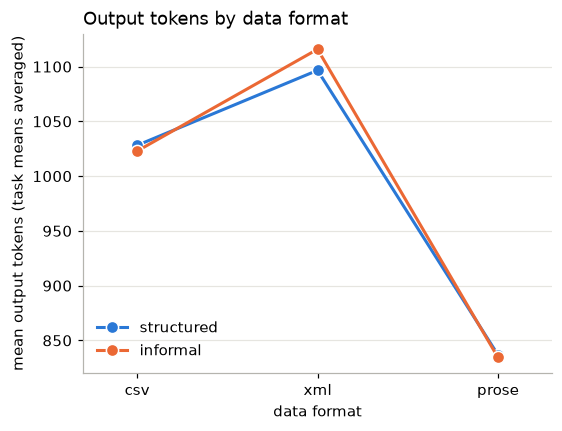

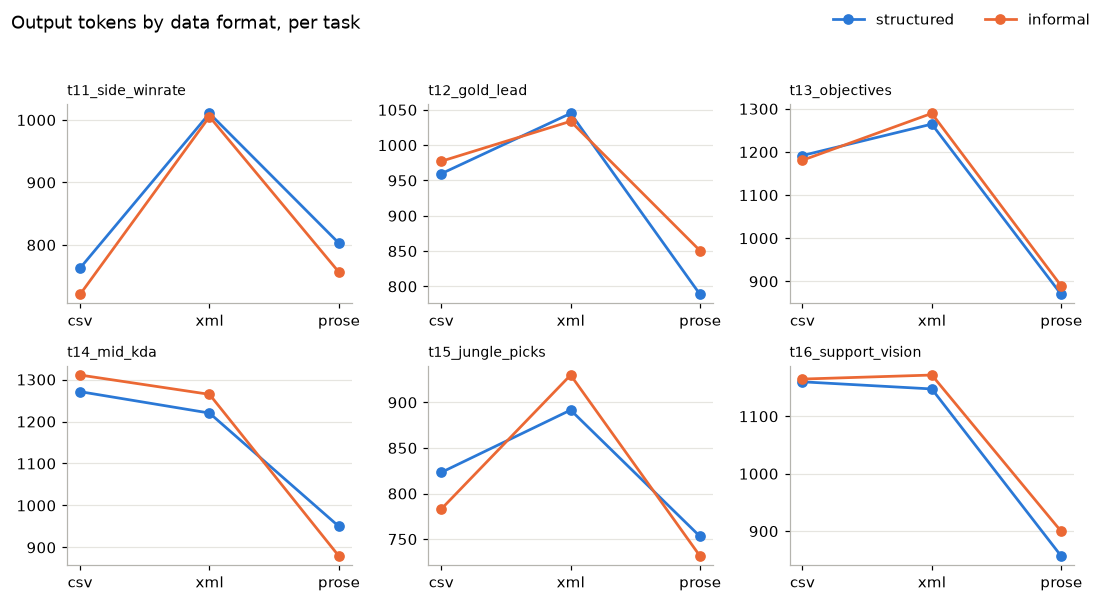

In [19]:
cell = valid.groupby(["task_id", "data_format", "format"])["output_tokens"].mean().reset_index()
means = cell.groupby(["data_format", "format"])["output_tokens"].mean().unstack().loc[DATA_FORMATS, FORMATS]

fig, ax = plt.subplots(figsize=(5.5, 4))
x = np.arange(len(DATA_FORMATS))
for f in FORMATS:
    ax.plot(x, means[f], marker="o", markersize=8, linewidth=2, color=COLORS[f], markeredgecolor="white", label=f)
ax.legend(frameon=False, loc="lower left")
ax.set_xticks(x, DATA_FORMATS)
ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
ax.set_xlabel("data format")
ax.set_ylabel("mean output tokens (task means averaged)")
ax.set_title("Output tokens by data format", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

# The same, task by task (small multiples).
tasks2 = sorted(cell["task_id"].unique())
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), sharey=False)
for ax, task_id in zip(axes.flat, tasks2):
    sub_cell = cell[cell["task_id"] == task_id].pivot(index="data_format", columns="format", values="output_tokens").reindex(DATA_FORMATS)
    for f in FORMATS:
        ax.plot(x, sub_cell[f], marker="o", markersize=6, linewidth=1.8, color=COLORS[f], label=f)
    ax.set_xticks(x, DATA_FORMATS)
    ax.set_title(task_id, fontsize=9, loc="left")
    ax.grid(axis="x", visible=False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper right", ncol=2)
fig.suptitle("Output tokens by data format, per task", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**How to read it:** if the lines rise from CSV to XML or prose, the model writes more when it has to convert a wordier format into Python. If the two lines run **parallel**, instruction format and data format act independently. If they **cross or diverge**, the effect of one depends on the other (an *interaction*). The small multiples show whether every task follows the same pattern.

**Result:** the two lines nearly overlap, so there's **no interaction**: instruction format doesn't change how data format affects output. XML gave the most output and prose the least on average. Task by task, prose was lowest in 5 of 6 tasks (not `t11_side_winrate`), and XML was highest in 4 of 6. CSV was highest in `t14_mid_kda` and tied with XML in `t16_support_vision`.

## B4. Input tokens by data format (what each format costs to send)

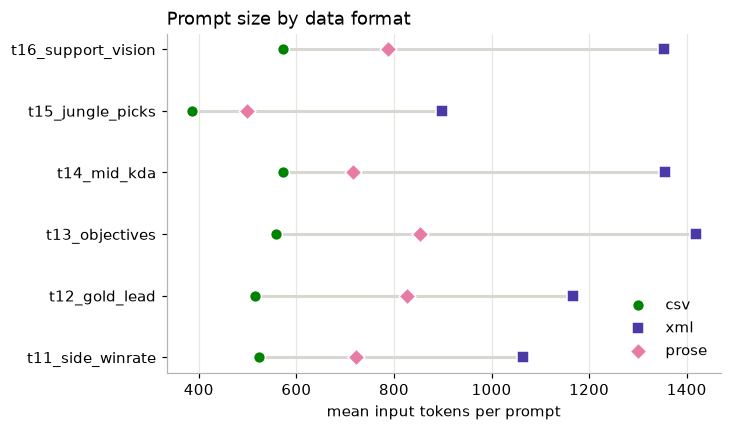

Input tokens relative to CSV, per task:


,xml / csv,prose / csv
task_id,,
t11_side_winrate,2.03,1.38
t12_gold_lead,2.27,1.61
t13_objectives,2.54,1.53
t14_mid_kda,2.36,1.25
t15_jungle_picks,2.33,1.29
t16_support_vision,2.37,1.38


In [20]:
inp = valid.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()[DATA_FORMATS]

fig, ax = plt.subplots(figsize=(6.5, 4))
y = np.arange(len(inp))
ax.hlines(y, inp.min(axis=1), inp.max(axis=1), color="#d8d7d1", linewidth=2, zorder=1)
for d in DATA_FORMATS:
    ax.scatter(inp[d], y, s=60, color=DATA_COLORS[d], marker=DATA_MARKERS[d], edgecolor="white", linewidth=1, zorder=2, label=d)
ax.set_yticks(y, inp.index)
ax.set_xlabel("mean input tokens per prompt")
ax.set_title("Prompt size by data format", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.show()

ratios = pd.DataFrame({f"{d} / csv": inp[d] / inp["csv"] for d in ["xml", "prose"]})
print("Input tokens relative to CSV, per task:")
display(ratios.round(2))

**How to read it:** each row is one task, and the three markers show its prompt size in each data format. The table shows how many times bigger the XML and prose prompts are than the CSV one.

**Result:** the order is the same in every task: CSV < prose < XML. XML prompts are 2.0–2.5× the CSV size and prose 1.25–1.6×. The extra XML cost comes from repeating each column name twice per row as tags.

## B5. How much of the input comes back as output?

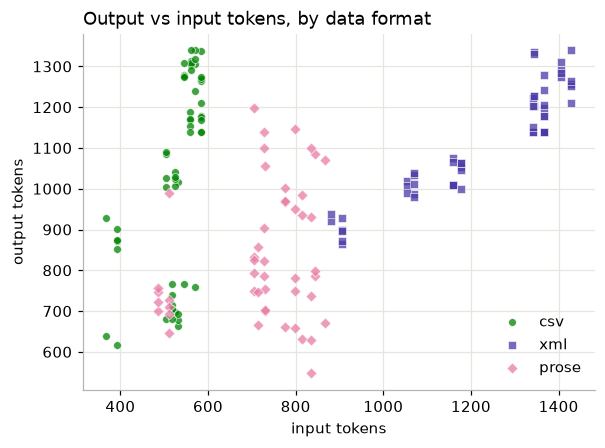

Output tokens per input token (task means averaged):


,mean output / input
data_format,
csv,1.97
xml,0.92
prose,1.16


In [21]:
valid["output_per_input"] = valid["output_tokens"] / valid["input_tokens"]

fig, ax = plt.subplots(figsize=(6, 4.2))
for d in DATA_FORMATS:
    sub_rows = valid[valid["data_format"] == d]
    ax.scatter(sub_rows["input_tokens"], sub_rows["output_tokens"], s=26, alpha=0.75, color=DATA_COLORS[d],
               marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5, label=d)
ax.set_xlabel("input tokens")
ax.set_ylabel("output tokens")
ax.set_title("Output vs input tokens, by data format", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

print("Output tokens per input token (task means averaged):")
ratio = valid.groupby(["task_id", "data_format"])["output_per_input"].mean().unstack()[DATA_FORMATS]
display(ratio.mean().round(2).to_frame("mean output / input"))

**How to read it:** each dot is one response. Because the model rewrites the data as Python, output tends to grow with input. But Python dictionaries cost about the same tokens however the data arrived, so a verbose format (XML) may show a *lower* output-to-input ratio. Its extra tokens are paid on input, not repeated on output.

**Result:** output per input token is about **1.97 for CSV**, 1.16 for prose, and **0.92 for XML**. CSV is the cheapest to send, but the model expands it the most when it writes it back as Python dicts. XML's verbosity is paid on input and not repeated on output, since Python dicts cost about the same however the data arrived. The CSV responses form two clusters (around 700 and 1,200–1,300 output tokens). Section B7 shows those are the two storage styles.

## B6. Paired comparisons within task

In [22]:
def describe_diff(diff, label, n_boot=10_000):
    """Mean difference with a bootstrap 95% CI (resampling pairs) and a Wilcoxon signed-rank p-value."""
    rng = np.random.default_rng(SEED)
    boot = rng.choice(diff.to_numpy(), size=(n_boot, len(diff)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    try:
        p = stats.wilcoxon(diff).pvalue
    except ValueError:
        p = np.nan
    return {"comparison": label, "n pairs": len(diff), "mean diff": round(diff.mean(), 1),
            "bootstrap 95% CI": f"[{lo:.1f}, {hi:.1f}]", "wilcoxon p": round(p, 4) if not np.isnan(p) else np.nan}

# Data format: per-task means averaged over instruction formats (6 pairs per comparison).
per_task = valid.groupby(["task_id", "data_format"])[["input_tokens", "output_tokens"]].mean().unstack()
rows = []
for metric in ["output_tokens", "input_tokens"]:
    for d in ["xml", "prose"]:
        rows.append(describe_diff(per_task[metric][d] - per_task[metric]["csv"], f"{metric}: {d} - csv"))
    rows.append(describe_diff(per_task[metric]["prose"] - per_task[metric]["xml"], f"{metric}: prose - xml"))

# Instruction format inside Experiment 2: one pair per task x data format (18 pairs).
per_cell = valid.groupby(["task_id", "data_format", "format"])[["input_tokens", "output_tokens"]].mean().unstack()
for metric in ["output_tokens", "input_tokens"]:
    diff = (per_cell[(metric, "informal")] - per_cell[(metric, "structured")]).dropna()
    rows.append(describe_diff(diff, f"{metric}: informal - structured"))

pd.DataFrame(rows).set_index("comparison")

,n pairs,mean diff,bootstrap 95% CI,wilcoxon p
comparison,,,,
output_tokens: xml - csv,6,78.2,"[5.1, 163.8]",0.1562
output_tokens: prose - csv,6,-191.4,"[-302.9, -67.4]",0.0625
output_tokens: prose - xml,6,-269.5,"[-332.7, -210.0]",0.0312
input_tokens: xml - csv,6,688.5,"[585.8, 786.6]",0.0312
input_tokens: prose - csv,6,212.9,"[156.1, 271.6]",0.0312
input_tokens: prose - xml,6,-475.6,"[-565.7, -388.2]",0.0312
output_tokens: informal - structured,18,3.9,"[-13.1, 20.3]",0.6705
input_tokens: informal - structured,18,-21.8,"[-23.3, -20.1]",0.0002


**How to read it:** each row compares two conditions *within the same task*, so differences between tasks cancel out. Data-format comparisons have only 6 pairs, and with 6 pairs the smallest possible Wilcoxon p-value is 0.03, so read the CI and the direction rather than the p-value. The last two rows repeat Experiment 1's question on the new tasks (18 pairs).

**Result:** for **input**, all six tasks agree: XML adds about 690 tokens over CSV (CI [586, 787]) and prose about 210 (CI [156, 272]). For **output**, prose used about 190 fewer tokens than CSV (CI [−303, −67]) and about 270 fewer than XML (CI [−333, −210], lower in all 6 tasks). XML vs CSV output is unclear (+78, CI [5, 164], p = 0.16). Instruction format, repeated on these tasks, **doesn't change output** (+4 tokens, CI [−13, 20], p = 0.67). Experiment 1's ~16-token informal saving doesn't show up when most of the output is copied data. The informal templates were still about 22 tokens shorter to send.

## B7. How did the model store the data?

In [23]:
def storage_style(code_text):
    """How the model wrote the 20 rows into its code: dicts with a key per value, or bare tuples/lists."""
    dict_rows = code_text.count('{"') + code_text.count("{'")          # {"team": ..., "side": ...}
    tuple_rows = sum(line.strip()[:2] in ('("', "('", '["', "['")      # ("DN Freecs", "blue", ...)
                     for line in code_text.splitlines())
    if dict_rows >= 15:
        return "dicts with keys"
    if tuple_rows >= 15:
        return "tuples/lists"
    return "other"

safe_model = MODEL.replace(":", "-").replace("/", "-")
style_rows = []
for path in Path("../data/raw").glob(f"*__{safe_model}.txt"):
    task_id, fmt, data_format, run, _ = path.stem.split("__")
    if data_format == "none":
        continue
    code_text = extract_code(path.read_text(encoding="utf-8"))
    style_rows.append({"task_id": task_id, "format": fmt, "data_format": data_format,
                       "run": int(run.removeprefix("run")), "style": storage_style(code_text)})
styles = pd.DataFrame(style_rows).merge(valid, on=["task_id", "format", "data_format", "run"])

print("How often each storage style was used (valid responses):")
display(pd.crosstab(styles["data_format"], styles["style"]).loc[DATA_FORMATS])
print("Mean output tokens by storage style:")
display(styles.groupby("style")["output_tokens"].agg(["count", "mean"]).round(0))
print("Mean output tokens by data format and storage style:")
display(styles.groupby(["data_format", "style"])["output_tokens"].agg(["count", "mean"]).round(0).loc[DATA_FORMATS])

How often each storage style was used (valid responses):


style,dicts with keys,other,tuples/lists
data_format,,,
csv,42,0,14
xml,54,0,0
prose,17,2,29


Mean output tokens by storage style:


,count,mean
style,,
dicts with keys,113,1118.0
other,2,606.0
tuples/lists,43,726.0


Mean output tokens by data format and storage style:


count    mean
data_format style                         
csv         dicts with keys     42  1158.0
            tuples/lists        14   700.0
xml         dicts with keys     54  1116.0
prose       dicts with keys     17  1028.0
            other                2   606.0
            tuples/lists        29   739.0

**How to read it:** this reads the saved answers in `data/raw/` (not committed to git, so it needs a local run) and classifies how the model wrote the 20 rows into Python: as **dicts with keys**, which repeat the column names on every row (`{"team": "Gen.G", "side": "red", ...}`), or as compact **tuples/lists** (`("Gen.G", "red", ...)`).

**Result:** storage style is the main driver of output tokens. Dict-with-keys answers averaged about 1,120 output tokens, while tuple/list answers averaged about 730, roughly 35% fewer for the same 20 rows. Data format strongly influences which style the model picks. From **XML**, whose tags already name every value, it used dicts in every valid response. From **CSV**, which has a header row, it mostly used dicts (42 of 56). From **prose**, which has no column names at all, it mostly used tuples (29 of 48). Within CSV alone, the dict answers averaged about 1,160 tokens against 700 for tuples. So prose's low output count in B2–B6 mostly reflects this choice of storage style, not the prose itself.

# Part C: All 280 rows together

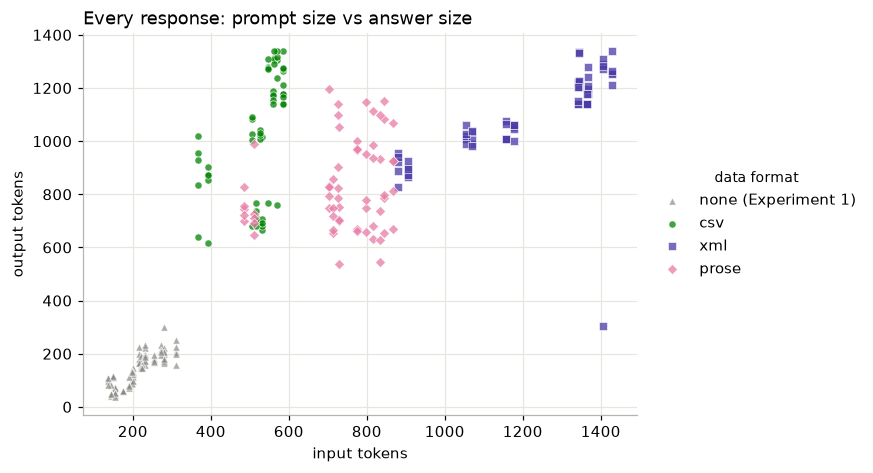

Spearman correlation, input vs output tokens, all rows: rho=0.82 (p=6.9e-68)


In [24]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(df["input_tokens"], df["output_tokens"], s=22, alpha=0.7, color=NEUTRAL, marker="^",
           edgecolor="white", linewidth=0.5, label="none (Experiment 1)")
for d in DATA_FORMATS:
    sub_rows = exp2[exp2["data_format"] == d]
    ax.scatter(sub_rows["input_tokens"], sub_rows["output_tokens"], s=22, alpha=0.75, color=DATA_COLORS[d],
               marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5, label=d)
ax.set_xlabel("input tokens")
ax.set_ylabel("output tokens")
ax.set_title("Every response: prompt size vs answer size", loc="left")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), title="data format", title_fontsize=9)
plt.show()

rho, p = stats.spearmanr(all_rows["input_tokens"], all_rows["output_tokens"])
print(f"Spearman correlation, input vs output tokens, all rows: rho={rho:.2f} (p={p:.2g})")

**How to read it:** Experiment 1 prompts (gray triangles) are short instructions, and their answers are short functions. Experiment 2 prompts carry data, and their answers carry it too, so they sit up and to the right. Within Experiment 2, the spread along each axis shows how much data format moves each cost.

**Result:** across all 280 responses, prompt size and answer size are strongly related (Spearman ρ = 0.82). Most of that comes from the two experiments sitting in different regions: short instructions with short answers, versus data-carrying prompts with data-carrying answers. Within Experiment 2, the format clusters line up left to right as CSV, prose, XML on the input axis, while prose sits lowest on the output axis.

## Overall summary

**Experiment 1 (instruction format, coding tasks):** informal prompts led to about 11% fewer output tokens (−16 per task, CI [−27, −6]), mostly through fewer code comments, with no significant change in correctness. Per *fully correct* solution, the formats tied.

**Experiment 2 (data format, LoL data tasks):**
- **XML is the expensive format:** about 2.3× the input of CSV and about 50% more total tokens per request.
- **CSV is cheapest to send** but is rewritten most expansively on output.
- **Prose costs more to send than CSV** but led to the least output, so CSV and prose come out about even in total.
- **The output differences mostly come from how the model chose to store the data** (B7): dicts with a column name on every value cost about 35% more output than bare tuples. Data format steers that choice.
- **Instruction format barely mattered** once the data was in the prompt, and it didn't interact with data format.
- **Validity:** 88% of responses were valid. Almost all failures were ordinary bugs, and only 2 of 180 skipped copying the data.

**Caveats:** one small local model (`qwen2.5-coder:7b`) at temperature 0.7, 6 data tasks of 20 rows each, one sentence template per row for prose, and a deliberately copy-heavy task design ("put the data in the code"). With 6 tasks, Wilcoxon p-values can't go below 0.03, so the direction-consistency counts and CIs carry more weight than the p-values.